In [7]:
import pandas as pd
df=pd.read_csv("student_performance_messy.csv")
df

,student_id,student_name,study_hours,attendance_percent,previous_score,sleep_hours,exam_score
0,S089,Nisha,5.2,81.0,33.0,6.9,61.0
1,S073,Rahul,5.4,100.0,63.0,7.5,86.0
2,S115,Pooja,4.5,100.0,69.0,6.7,84.0
3,S159,Aarav,5.3,84.0,69.0,5.5,71.0
4,S164,priya,1.8,85.0,78.0,7.1,74.0
...,...,...,...,...,...,...,...
200,S018,NaN,NaN,92.0,69.0,6.4,76.0
201,S099,Aditya,4.5,99.0,66.0,6.0,86.0
202,S067,Riya,4.5,71.0,66.0,6.2,78.0
203,S127,Meera,1.5,100.0,62.0,6.5,58.0


In [8]:
df.head

<bound method NDFrame.head of     student_id student_name study_hours attendance_percent previous_score  \
0         S089        Nisha         5.2               81.0           33.0   
1         S073        Rahul         5.4              100.0           63.0   
2         S115        Pooja         4.5              100.0           69.0   
3         S159        Aarav         5.3               84.0           69.0   
4         S164        priya         1.8               85.0           78.0   
..         ...          ...         ...                ...            ...   
200       S018          NaN         NaN               92.0           69.0   
201       S099       Aditya         4.5               99.0           66.0   
202       S067         Riya         4.5               71.0           66.0   
203       S127        Meera         1.5              100.0           62.0   
204       S110        Kabir         3.1               88.0           61.0   

     sleep_hours  exam_score  
0            6

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          205 non-null    str    
 1   student_name        201 non-null    str    
 2   study_hours         193 non-null    str    
 3   attendance_percent  194 non-null    str    
 4   previous_score      195 non-null    str    
 5   sleep_hours         193 non-null    float64
 6   exam_score          197 non-null    float64
dtypes: float64(2), str(5)
memory usage: 11.3 KB


In [10]:
df.isnull().sum().sum()

np.int64(57)

In [11]:
df.duplicated().sum()

np.int64(5)

In [13]:
df.loc[[6, 25, 28, 107]]

,student_id,student_name,study_hours,attendance_percent,previous_score,sleep_hours,exam_score
6,S186,Arjun,1.8 hrs,75.0,70.0,8.9,65.0
25,S105,Yash,1.5,88.0,55 / 100,7.7,57.0
28,S072,Sana,2.7,81%,60.0,7.4,61.0
107,S172,Ishaan,3.5,eighty,NaN,6.3,74.0


In [16]:

df = df.drop_duplicates()
cols = ["study_hours", "attendance_percent", "previous_score"]

for col in cols:

    df[col] = df[col].astype("string").str.strip().str.lower()

    df[col] = df[col].replace({
        "eighty": "80"
    })

    df[col] = df[col].str.replace(
        r"\s*hrs?\s*$", "", regex=True
    )

    df[col] = df[col].str.replace(
        r"\s*%", "", regex=True
    )

    df[col] = df[col].str.replace(
        r"\s*/\s*100\s*$", "", regex=True
    )

    df[col] = pd.to_numeric(df[col], errors="coerce")

In [17]:
limits={"study_hours":24,
        "attendance_percent":100,
        "previous_score":100}
for col, top in limits.items():
    df.loc[df[col]>top,col]=None
df.loc[df.sleep_hours<0,"sleep_hours"]=None
df=df[df.exam_score<=100]

In [18]:
len(df)

191

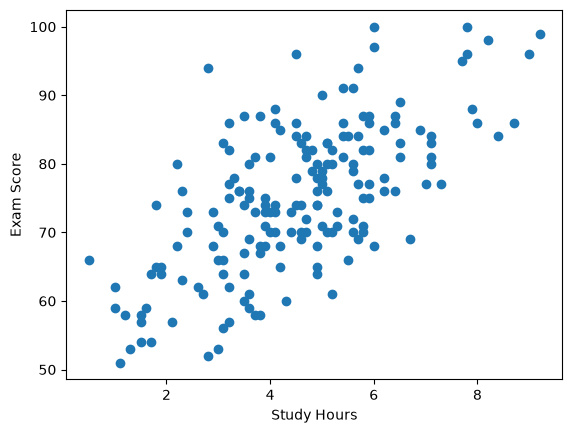

In [19]:
import matplotlib.pyplot as plt
plt.scatter(df.study_hours, df.exam_score)
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.show()

In [20]:
from sklearn.model_selection import train_test_split
X = df[["study_hours", "attendance_percent", "previous_score", "sleep_hours"]]
y = df["exam_score"]
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [21]:
medians = x_train.median()
x_train = x_train.fillna(medians)
x_test = x_test.fillna(medians)

In [22]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(random_state=42)
model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [23]:
from sklearn.metrics import mean_absolute_error 
predictions=model.predict(x_test)
mae = mean_absolute_error(y_test, predictions)
print("MAE:",round(mae,1))

MAE: 6.0


In [24]:
new_student = pd.DataFrame({
    "study_hours": [6],
    "attendance_percent": [90],
    "previous_score": [75],
    "sleep_hours": [8],
})
score=model.predict(new_student)[0]
print("Predicted score:",round(score))

Predicted score: 85
